import the required modules:

In [2]:
from pathlib import Path

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import pandas as pd

In [4]:
# set some variables
PROJECT_ROOT = Path("pyproject.toml").resolve().parent.parent
PURIFIER = PROJECT_ROOT / "data" / "raw" / "purifier.csv"
NON_PURIFIER = PROJECT_ROOT / "data" / "raw" / "non-purifier.csv"
RESULT = PROJECT_ROOT / "results" / "output.png"

show = True

print(PROJECT_ROOT)
print(NON_PURIFIER)

/home/zhori/probe/air-quality-ml
/home/zhori/probe/air-quality-ml/data/raw/non-purifier.csv


Saved /home/zhori/probe/air-quality-ml/results/output.png


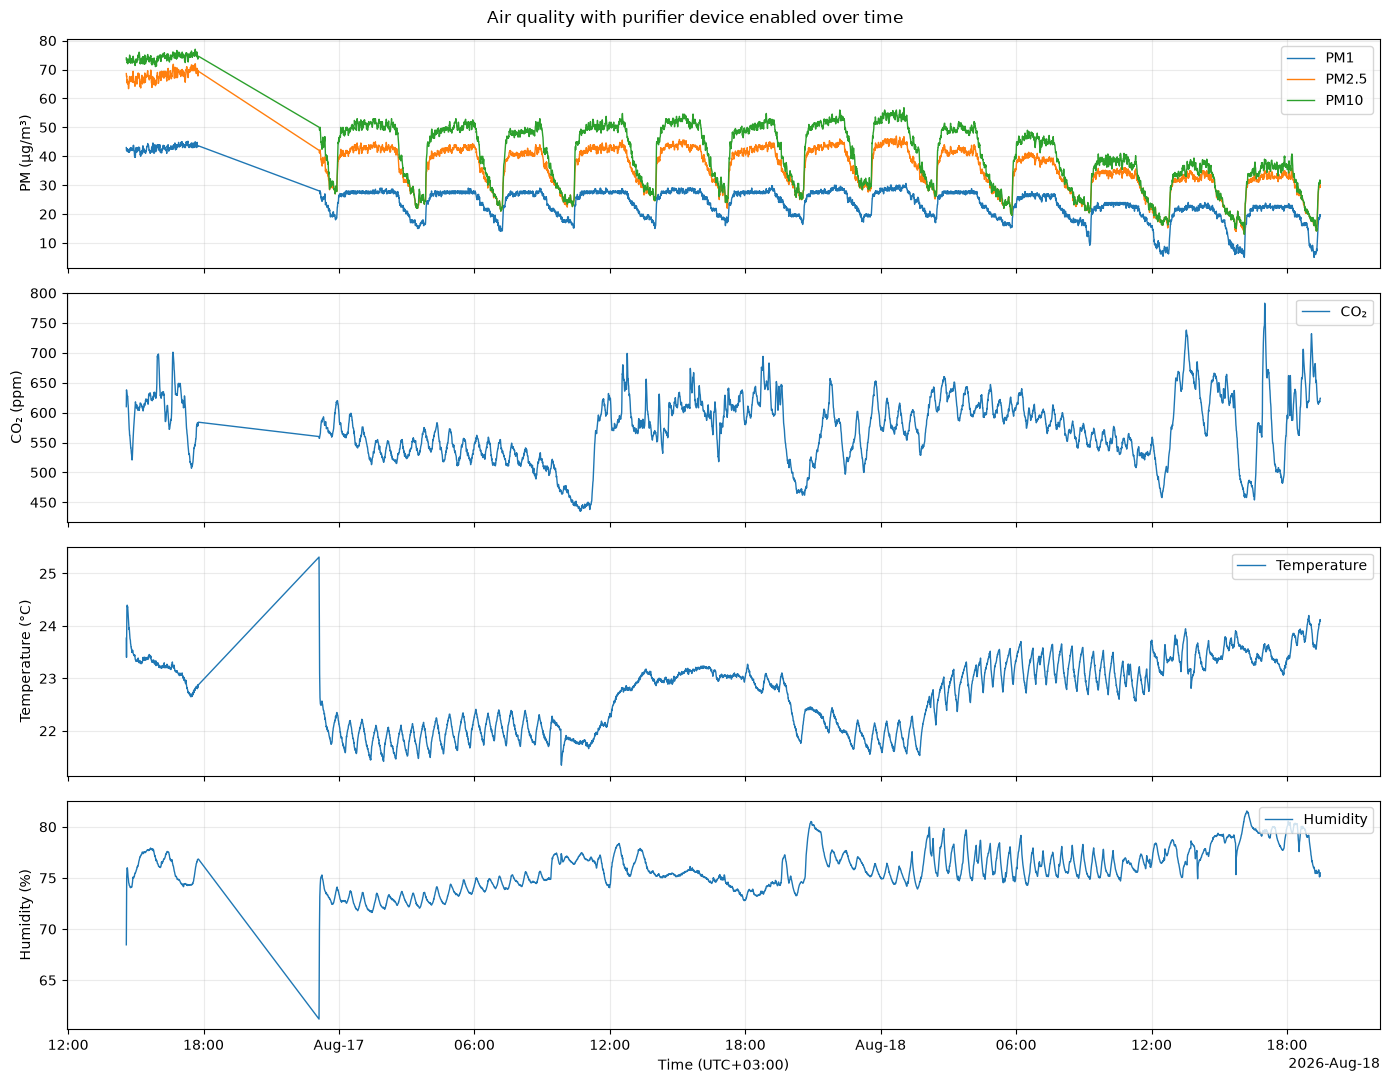

In [6]:
data = (
    pd.read_csv(
        PURIFIER,
        parse_dates=["timestamp"],
    )
    .sort_values("timestamp")
    .reset_index(drop=True)
)
figure, axes = plt.subplots(4, 1, figsize=(14, 11), sharex=True)
panels = [
    (
        ["pm1_ugm3", "pm25_ugm3", "pm10_ugm3"],
        ["PM1", "PM2.5", "PM10"],
        "PM (µg/m³)",
    ),
    (["co2_ppm"], ["CO₂"], "CO₂ (ppm)"),
    (["temperature_c"], ["Temperature"], "Temperature (°C)"),
    (["humidity_pct"], ["Humidity"], "Humidity (%)"),
]
for axis, (columns, labels, ylabel) in zip(axes, panels, strict=True):
    for column, label in zip(columns, labels, strict=True):
        axis.plot(data["timestamp"], data[column], label=label, linewidth=1)
    axis.set_ylabel(ylabel)
    axis.grid(alpha=0.25)
    axis.legend(loc="upper right")

if "event" in data.columns:
    events = data.loc[data["event"].fillna("").str.strip().ne("")]
    for _, event in events.iterrows():
        for axis in axes:
            axis.axvline(event["timestamp"], color="gray", linestyle="--", alpha=0.5)
        axes[0].annotate(
            str(event["event"]),
            xy=(event["timestamp"], 1),
            xycoords=("data", "axes fraction"),
            xytext=(3, -5),
            textcoords="offset points",
            rotation=90,
            va="top",
            fontsize=8,
        )

timezone = data["timestamp"].dt.tz
locator = mdates.AutoDateLocator(tz=timezone)
axes[-1].xaxis.set_major_locator(locator)
axes[-1].xaxis.set_major_formatter(mdates.ConciseDateFormatter(locator, tz=timezone))
axes[-1].set_xlabel(f"Time ({timezone or 'local'})")
figure.suptitle("Air quality with purifier device enabled over time")
figure.tight_layout()
figure.savefig(RESULT, dpi=150)
print(f"Saved {RESULT}")

if show:
    plt.show()
plt.close(figure)

In [4]:
target_name = "pm25_ugm3"
target = data[target_name]

data_new = data.drop(columns=[target_name])
data_new.columns

Index(['timestamp', 'co2_ppm', 'temperature_c', 'humidity_pct', 'pm1_ugm3',
       'pm10_ugm3', 'event'],
      dtype='str')

In [5]:
print(
    f"The dataset contains {data_new.shape[0]} samples and {data_new.shape[1]} features"
)

The dataset contains 5524 samples and 7 features


In [6]:
# start training
from sklearn import

SyntaxError: Expected one or more names after 'import' (83829337.py, line 2)